# 01 · Exploratory analysis: where does Olist make money, and where does it lose customers?

**Data:** the Olist Brazilian e-commerce public dataset (CC BY-NC-SA 4.0): 99,441 orders placed from September 2016 to October 2018, spread over 9 tables. Trend charts use **Jan 2017 to Aug 2018** because the months at either end are partial.

**Method:** every chart is driven by one of the portable SQL queries in [`sql/`](../sql). The same SQL runs on DuckDB here and on Postgres in CI. Each chart is followed by a **So what** takeaway.

**Definitions:** an order is *valid* unless it is `canceled` or `unavailable`. *GMV* is item price plus freight. A *customer* is a `customer_unique_id`; `customer_id` changes with every order.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from olist.plotting import INK_SECONDARY, SEQUENTIAL, SERIES, save, use_style
from olist.warehouse import connect, run_sql_file

use_style()
con = connect()
pd.set_option("display.float_format", "{:,.4f}".format)
print(con.execute("SELECT COUNT(*) AS orders, MIN(order_purchase_timestamp) AS first, MAX(order_purchase_timestamp) AS last FROM orders").df())

   orders               first                last
0   99441 2016-09-04 21:15:19 2018-10-17 17:30:18


## Q1. How fast is the business growing?

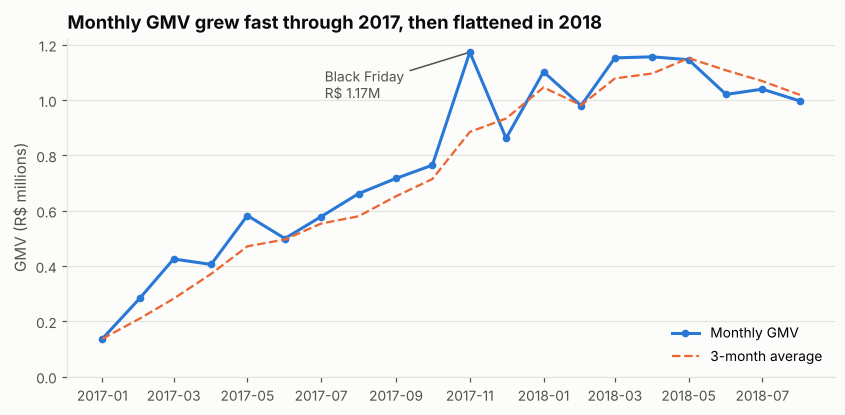

Total GMV Jan 2017 - Aug 2018: R$ 15,688,397
Jan-Aug 2018 vs Jan-Aug 2017: +140.4%
Mean MoM growth Feb-Aug 2018: -1.0%


,month,orders,gmv,aov,mom_growth,yoy_growth
12,2018-01-01,7187,"1,102,475.2700",153.3985,0.2785,7.0506
13,2018-02-01,6624,"980,154.6000",147.9702,-0.1110,2.4566
14,2018-03-01,7168,"1,152,785.4500",160.8239,0.1761,1.7085
15,2018-04-01,6919,"1,156,634.9200",167.1679,0.0033,1.8499
16,2018-05-01,6833,"1,146,158.0600",167.7386,-0.0091,0.9669
17,2018-06-01,6145,"1,020,606.1000",166.0872,-0.1095,1.0426
18,2018-07-01,6233,"1,039,816.8400",166.8245,0.0188,0.7966
19,2018-08-01,6421,"997,040.0300",155.2780,-0.0411,0.5061


In [2]:
monthly = run_sql_file(con, "01_monthly_revenue_mom")
monthly["month"] = pd.to_datetime(monthly["month"])
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly["month"], monthly["gmv"] / 1e6, color=SERIES[0], marker="o", markersize=4, label="Monthly GMV")
ax.plot(monthly["month"], monthly["gmv_3m_avg"] / 1e6, color=SERIES[1], linestyle="--", linewidth=1.5, label="3-month average")
peak = monthly.loc[monthly["gmv"].idxmax()]
ax.annotate(f"Black Friday\nR$ {peak.gmv / 1e6:.2f}M", (peak.month, peak.gmv / 1e6), xytext=(-95, -30),
            textcoords="offset points", fontsize=9, color=INK_SECONDARY, arrowprops=dict(arrowstyle="-", color=INK_SECONDARY))
ax.set_ylabel("GMV (R$ millions)")
ax.set_title("Monthly GMV grew fast through 2017, then flattened in 2018")
ax.legend(loc="lower right")
ax.set_ylim(0)
save(fig, "monthly_gmv")
plt.show()

jan_aug = lambda y: monthly[(monthly.month.dt.year == y) & (monthly.month.dt.month <= 8)].gmv.sum()
print(f"Total GMV Jan 2017 - Aug 2018: R$ {monthly.gmv.sum():,.0f}")
print(f"Jan-Aug 2018 vs Jan-Aug 2017: {jan_aug(2018) / jan_aug(2017) - 1:+.1%}")
print(f"Mean MoM growth Feb-Aug 2018: {monthly[monthly.month >= '2018-02-01'].mom_growth.mean():+.1%}")
monthly[["month", "orders", "gmv", "aov", "mom_growth", "yoy_growth"]].tail(8)

**So what.**
- Jan to Aug 2018 GMV was **+140%** on the same months of 2017. Olist is still a young marketplace.
- Growth has **stalled**. Mean MoM growth from Feb to Aug 2018 was **−1.0%**, and monthly GMV stayed between R\$ 1.0M and R\$ 1.16M.
- Black Friday (Nov 2017, **R\$ 1.17M, +53% MoM**) is the single biggest month. It gives a clear seasonal lever.
- Average order value moves only within R\$ 147–174, so growth came from **more orders, not bigger baskets**. The next stage of growth has to come from repeat purchases or basket size, which the rest of this notebook examines.

## Q2. Which categories matter?

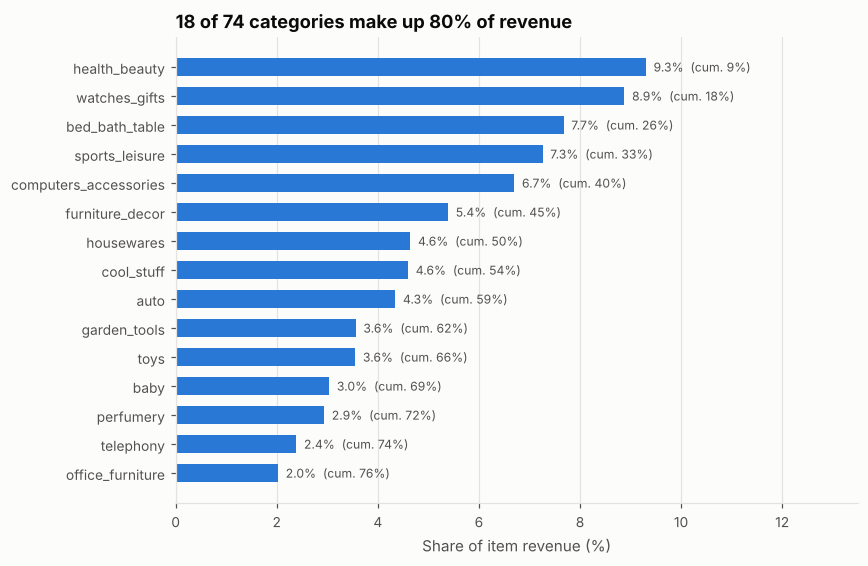

,revenue_rank,category,items,orders,revenue,revenue_share,cumulative_share,in_pareto_core
0,1,health_beauty,9634,8800,"1,255,695.1300",0.0931,0.0931,1
1,2,watches_gifts,5970,5604,"1,198,185.2100",0.0888,0.1818,1
2,3,bed_bath_table,11097,9399,"1,035,964.0600",0.0768,0.2586,1
3,4,sports_leisure,8590,7673,"979,740.9200",0.0726,0.3312,1
4,5,computers_accessories,7781,6654,"904,322.0200",0.0670,0.3982,1


In [3]:
pareto = run_sql_file(con, "06_category_pareto")
core = int(pareto.in_pareto_core.sum())
top = pareto.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.category, top.revenue_share * 100, color=SERIES[0], height=0.6)
for y, (share, cum) in enumerate(zip(top.revenue_share, top.cumulative_share)):
    ax.text(share * 100 + 0.15, y, f"{share:.1%}  (cum. {cum:.0%})", va="center", fontsize=8, color=INK_SECONDARY)
ax.set_xlabel("Share of item revenue (%)")
ax.set_title(f"{core} of {len(pareto)} categories make up 80% of revenue")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlim(0, top.revenue_share.max() * 100 * 1.45)
save(fig, "category_pareto")
plt.show()
pareto.head(5)

**So what.**
- Revenue is spread more evenly than a classic 80/20: **18 of 74 categories** make up 80% of item revenue, and the largest, `health_beauty`, has only **9.3%**.
- The top three (`health_beauty`, `watches_gifts`, `bed_bath_table`) together make up **25.9%**. Category managers for these three cover a quarter of the business.
- With no single dominant category, Olist is a general marketplace. Retention and delivery levers apply to the whole platform, not to one vertical.

## Q3. Do customers come back?

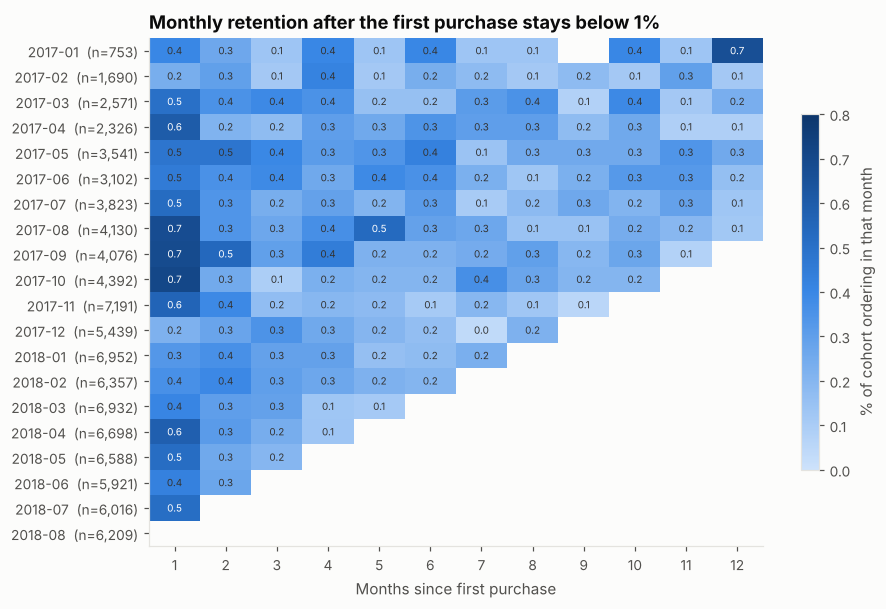

Mean month-1 retention across cohorts: 0.48%
Mean cumulative months 1-6 (cohorts with 6 months observed): 1.89%


In [4]:
cohort = run_sql_file(con, "02_cohort_retention")
heat = cohort.pivot(index="cohort_month", columns="months_since_first", values="retention")
heat.index = pd.to_datetime(heat.index).strftime("%Y-%m")
sizes = cohort[cohort.months_since_first == 0].set_index("cohort_month").cohort_size
view = heat.loc[:, 1:12] * 100
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(view.to_numpy(), cmap=SEQUENTIAL, aspect="auto", vmin=0, vmax=0.8)
ax.set_xticks(range(view.shape[1]), view.columns)
ax.set_yticks(range(view.shape[0]), [f"{m}  (n={n:,})" for m, n in zip(view.index, sizes)])
ax.set_xlabel("Months since first purchase")
ax.set_title("Monthly retention after the first purchase stays below 1%")
ax.grid(False)
for (i, j), v in np.ndenumerate(view.to_numpy()):
    if not np.isnan(v):
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6.5, color="white" if v > 0.5 else "#333")
cb = fig.colorbar(im, ax=ax, shrink=0.7)
cb.set_label("% of cohort ordering in that month")
save(fig, "cohort_heatmap")
plt.show()
print(f"Mean month-1 retention across cohorts: {heat[1].mean():.2%}")
print(f"Mean cumulative months 1-6 (cohorts with 6 months observed): {heat.loc[:, 1:6].dropna().sum(axis=1).mean():.2%}")

**So what.**
- Month-1 retention averages **0.48%** across cohorts. Fewer than 1 in 200 new customers order again the next month.
- Adding up months 1 to 6, only about **1.9%** of a cohort comes back within half a year. No cohort improves on this, so nothing Olist did in 2017 or 2018 changed repeat behaviour.
- Olist runs almost entirely on **acquisition**. A retention programme does not need to be good to matter, because the base is so low. This is the starting point for the segmentation (03) and churn (04) notebooks.

## Q4. Does late delivery hurt reviews?

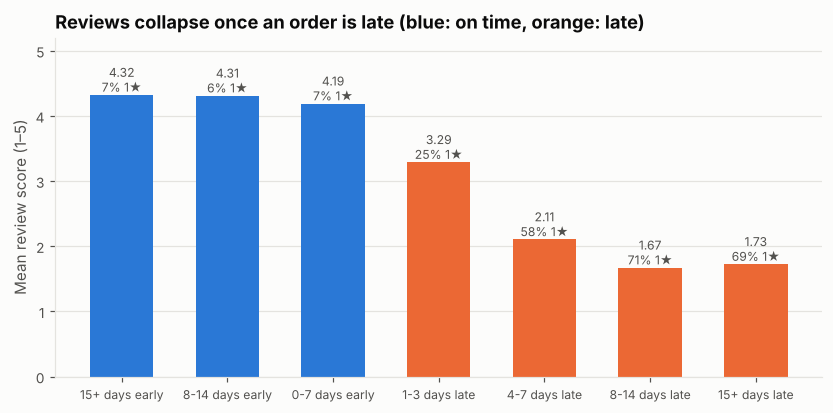

Late orders: 6.7% of delivered, reviewed orders


,bucket_order,delay_bucket,orders,order_share,avg_review,share_1_star,share_5_star
0,1,15+ days early,34771,0.3629,4.3230,0.0651,0.6421
1,2,8-14 days early,36158,0.3773,4.3112,0.0637,0.6298
2,3,0-7 days early,18514,0.1932,4.1894,0.0712,0.5695
3,4,1-3 days late,1852,0.0193,3.2910,0.2511,0.3315
4,5,4-7 days late,1748,0.0182,2.1055,0.5847,0.1407
5,6,8-14 days late,1446,0.0151,1.6715,0.7061,0.0685
6,7,15+ days late,1335,0.0139,1.7258,0.6876,0.0719


In [5]:
delay = run_sql_file(con, "04_delivery_delay_vs_review")
fig, ax = plt.subplots(figsize=(9, 4))
colors = [SERIES[0] if b <= 3 else SERIES[1] for b in delay.bucket_order]
bars = ax.bar(delay.delay_bucket, delay.avg_review, color=colors, width=0.6)
for b, n, s1 in zip(bars, delay.orders, delay.share_1_star):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.05, f"{b.get_height():.2f}\n{s1:.0%} 1★", ha="center", fontsize=8, color=INK_SECONDARY)
ax.set_ylim(0, 5.2)
ax.set_ylabel("Mean review score (1–5)")
ax.set_title("Reviews collapse once an order is late (blue: on time, orange: late)")
ax.tick_params(axis="x", labelsize=8)
save(fig, "delay_vs_review")
plt.show()
late_share = delay[delay.bucket_order >= 4].orders.sum() / delay.orders.sum()
print(f"Late orders: {late_share:.1%} of delivered, reviewed orders")
delay

**So what.**
- **93.3%** of orders arrive on or before the promised date, and they average **4.19–4.32 stars** with 6–7% 1-star reviews.
- Lateness has a cliff, not a slope. Arriving **1–3 days late** drops the mean to **3.29** (25% 1-star). At **4–7 days late** it is **2.11** (58% 1-star), and past a week it is **≈1.7** (69–71% 1-star).
- Late orders are only **6.7%** of volume but cause a disproportionate share of 1-star reviews. Notebook 02 tests whether the effect survives controls for category and state.

## Q5. Where is delivery worst?

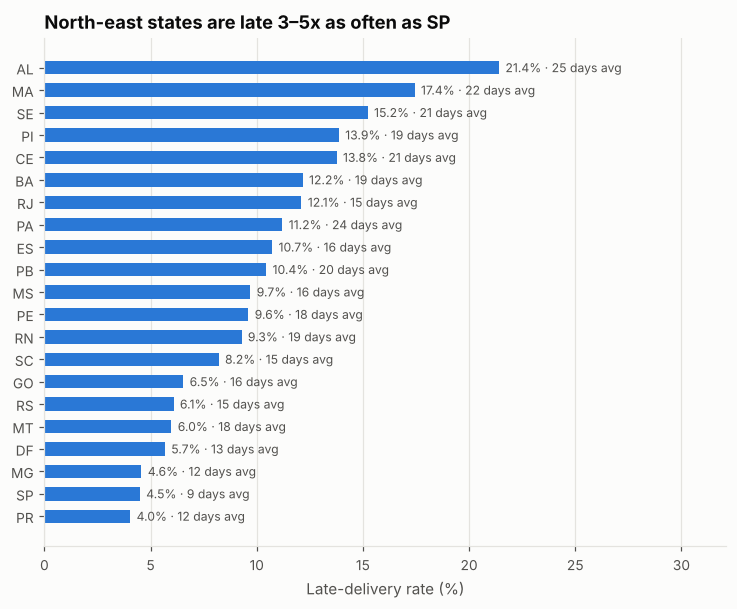

,hotspot_rank,lane,orders,late_orders,late_rate,avg_days_late_when_late,share_of_all_late
0,1,SP -> AL,255,61.0000,0.2392,9.2623,0.0103
1,2,SP -> MA,491,93.0000,0.1894,10.1613,0.0156
2,3,SP -> PI,329,54.0000,0.1641,14.4444,0.0091
3,4,SP -> SE,208,34.0000,0.1635,15.9118,0.0057
4,5,SP -> RJ,8158,"1,152.0000",0.1412,13.4332,0.1937
5,6,SP -> CE,969,133.0000,0.1373,13.9323,0.0224
6,7,SP -> BA,2307,297.0000,0.1287,10.1919,0.0499
7,8,SP -> MS,477,59.0000,0.1237,8.5254,0.0099


In [6]:
sla = run_sql_file(con, "09_state_delivery_sla").sort_values("late_rate")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(sla.customer_state, sla.late_rate * 100, color=SERIES[0], height=0.6)
for y, (lr, d) in enumerate(zip(sla.late_rate, sla.avg_delivery_days)):
    ax.text(lr * 100 + 0.3, y, f"{lr:.1%} · {d:.0f} days avg", va="center", fontsize=8, color=INK_SECONDARY)
ax.set_xlabel("Late-delivery rate (%)")
ax.set_title("North-east states are late 3–5x as often as SP")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlim(0, sla.late_rate.max() * 100 * 1.5)
save(fig, "state_late_rate")
plt.show()
hot = run_sql_file(con, "13_late_delivery_hotspots")
hot.head(8)

**So what.**
- Late rates range from **4.0% (PR) and 4.5% (SP)** to **21.4% in Alagoas (AL)** and **17.4% in Maranhão (MA)**. Average delivery takes **8.7 days** in SP and **24.5 days** in AL.
- The worst lanes all start in SP. Volume matters more than rate, though: **SP → RJ** has a 14.1% late rate on 8,158 orders and alone accounts for **19.4% of all late deliveries** (query 13).
- Two different fixes follow. For small north-east lanes, **pad the estimate** (customers forgive slow but not late, see Q4). For SP → RJ, fix the **carrier performance** itself.

## Q6. How do customers pay?

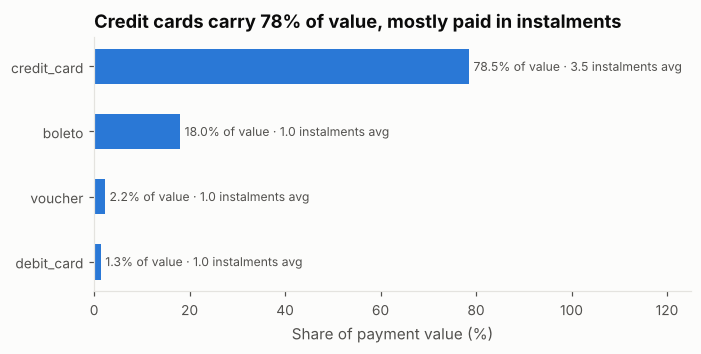

,payment_type,orders,order_share,value_share,avg_payment_value,avg_installments,share_multi_installment
0,credit_card,75618,0.7700,0.7847,162.7039,3.5061,0.6687
1,boleto,19539,0.1990,0.1796,144.6749,1.0009,0.0001
2,voucher,3745,0.0381,0.0222,62.3329,1.0000,0.0000
3,debit_card,1515,0.0154,0.0135,140.1172,1.0000,0.0000


In [7]:
pay = run_sql_file(con, "07_payment_mix")
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(pay.payment_type[::-1], pay.value_share[::-1] * 100, color=SERIES[0], height=0.55)
for y, (v, inst) in enumerate(zip(pay.value_share[::-1], pay.avg_installments[::-1])):
    ax.text(v * 100 + 1, y, f"{v:.1%} of value · {inst:.1f} instalments avg", va="center", fontsize=8, color=INK_SECONDARY)
ax.set_xlim(0, 125)
ax.set_xlabel("Share of payment value (%)")
ax.set_title("Credit cards carry 78% of value, mostly paid in instalments")
ax.grid(axis="y", visible=False)
plt.show()
pay

**So what.**
- Credit cards take **78.5% of payment value** (77.0% of orders). **66.9%** of card payments are split into instalments, averaging **3.5**.
- Boleto (bank slip) still takes **19.9% of orders**. These customers cannot use instalments, so any "pay later" or Pix-style option should be tested on this group first.
- Instalments are how Brazilians afford larger baskets. Promotions should be framed as "*n* × R\$ X interest-free" rather than as a discount.

## Q7. How big are baskets, and what does a second item do?

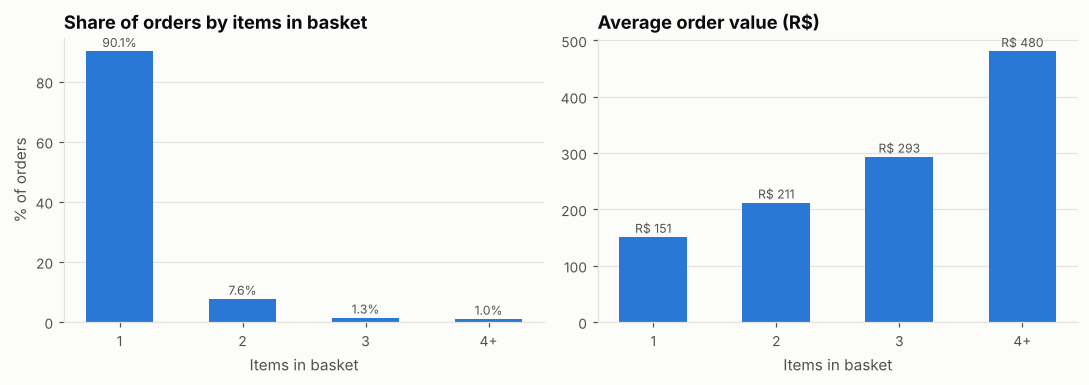

,basket_size,orders,order_share,avg_order_value,avg_freight_per_item,avg_distinct_products,avg_review
0,1,88438,0.9006,150.5289,20.4185,1.0000,4.1725
1,2,7489,0.0763,211.4422,18.6112,1.3348,3.6609
2,3,1319,0.0134,292.9120,18.3833,1.5375,3.5131
3,4+,953,0.0097,480.4822,18.7239,1.5645,3.3380


In [8]:
basket = run_sql_file(con, "11_basket_size")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].bar(basket.basket_size, basket.order_share * 100, color=SERIES[0], width=0.55)
axes[0].set_title("Share of orders by items in basket")
axes[0].set_ylabel("% of orders")
for x, v in enumerate(basket.order_share):
    axes[0].text(x, v * 100 + 1.5, f"{v:.1%}", ha="center", fontsize=8, color=INK_SECONDARY)
axes[1].bar(basket.basket_size, basket.avg_order_value, color=SERIES[0], width=0.55)
axes[1].set_title("Average order value (R$)")
for x, v in enumerate(basket.avg_order_value):
    axes[1].text(x, v + 8, f"R$ {v:.0f}", ha="center", fontsize=8, color=INK_SECONDARY)
for a in axes:
    a.set_xlabel("Items in basket")
plt.tight_layout()
plt.show()
basket

**So what.**
- **90.1%** of orders contain a single item. Two-item baskets average **R\$ 211** against **R\$ 151** for one item.
- Freight per item barely falls with basket size (R\$ 20.4 → R\$ 18.6), so customers get almost **no shipping incentive to add a second item**. That is the gap a free-shipping threshold would close. The simulated A/B test in notebook 02 uses the real **9.9% multi-item rate** as its baseline.
- Caution: mean review falls from **4.17 (1 item) to 3.34 (4+ items)**, probably because multi-seller orders arrive in several parcels. Any basket-building test needs review score as a guardrail.

## Q8. When customers come back, how quickly?

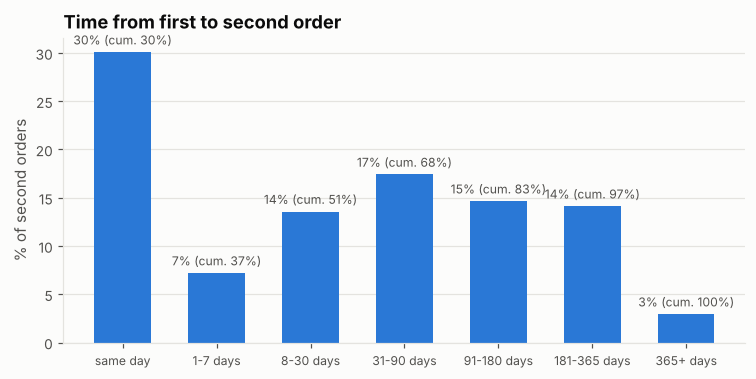

,bucket_order,gap_bucket,customers,share,cumulative_share,median_gap_days
0,1,same day,869,0.3009,0.3009,28.0000
1,2,1-7 days,208,0.0720,0.3729,28.0000
2,3,8-30 days,392,0.1357,0.5087,28.0000
3,4,31-90 days,503,0.1742,0.6828,28.0000
4,5,91-180 days,423,0.1465,0.8293,28.0000
5,6,181-365 days,408,0.1413,0.9706,28.0000
6,7,365+ days,85,0.0294,1.0000,28.0000


In [9]:
gap = run_sql_file(con, "12_time_to_second_order")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(gap.gap_bucket, gap.share * 100, color=SERIES[0], width=0.6)
for x, (s, c) in enumerate(zip(gap.share, gap.cumulative_share)):
    ax.text(x, s * 100 + 0.8, f"{s:.0%} (cum. {c:.0%})", ha="center", fontsize=8, color=INK_SECONDARY)
ax.set_ylabel("% of second orders")
ax.set_title("Time from first to second order")
ax.tick_params(axis="x", labelsize=8)
plt.show()
gap

**So what.**
- **30%** of "repeat" customers placed their second order on the **same day** as the first. Many of these are one shopping session split into two orders, so true loyalty is even lower than the 3% repeat rate suggests.
- Among real returns, **68%** of all second orders arrive within 90 days and **83%** within 180 days (median 28 days including same-day orders).
- Win-back campaigns should run between **day 30 and day 90**. After 180 days a one-time buyer is very unlikely to return. The churn model in notebook 04 therefore uses a 180-day label window.

## Q9. When do people shop?

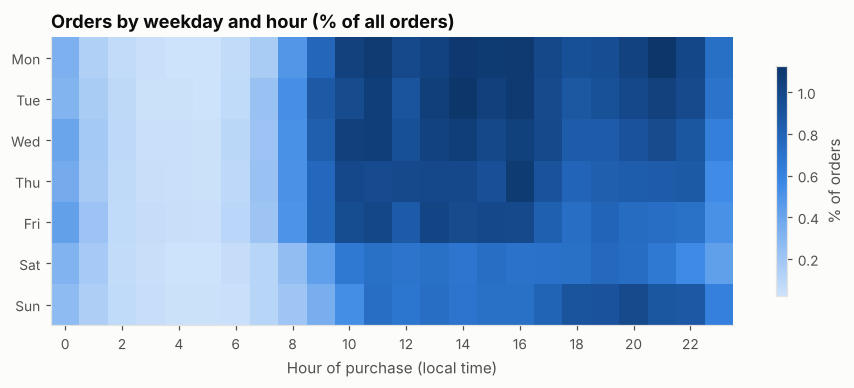

day_name
Mon    16.3%
Tue    16.0%
Wed    15.6%
Thu    14.8%
Fri    14.2%
Sun    12.0%
Sat    11.0%


In [10]:
timing = run_sql_file(con, "16_purchase_timing")
grid = timing.pivot(index="day_name", columns="hour_of_day", values="order_share").reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
fig, ax = plt.subplots(figsize=(10, 3.4))
im = ax.imshow(grid.to_numpy() * 100, cmap=SEQUENTIAL, aspect="auto")
ax.set_yticks(range(7), grid.index)
ax.set_xticks(range(0, 24, 2), range(0, 24, 2))
ax.set_xlabel("Hour of purchase (local time)")
ax.set_title("Orders by weekday and hour (% of all orders)")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8).set_label("% of orders")
plt.show()
day = timing.groupby("day_name").orders.sum() / timing.orders.sum()
print(day.sort_values(ascending=False).map("{:.1%}".format).to_string())

**So what.**
- Demand peaks on **Monday (16.3%) and Tuesday (16.0%)** and is lowest on **Saturday (11.0%)**. Each hour from 10:00 to 22:00 carries roughly **6%** of orders, so evenings are as strong as office hours.
- Campaign emails should go out **Sunday evening or Monday morning**. Customer-service staffing should follow the 10:00–22:00 plateau, not a 9-to-5 shift.

## Q10. What do review texts complain about?

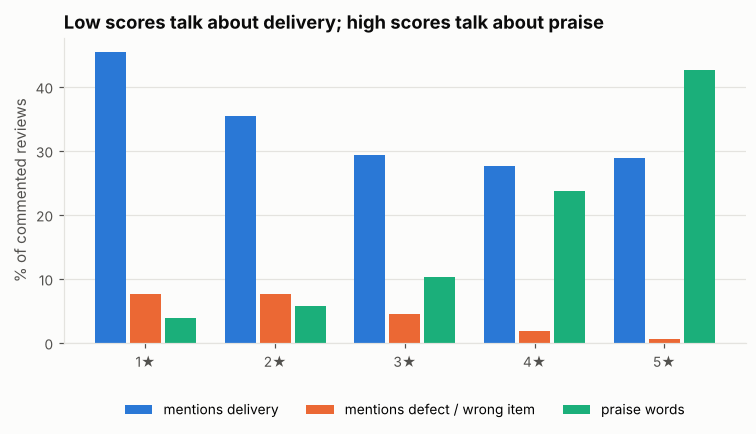

,review_score,reviews,share_with_comment,avg_comment_length,delivery_mention_rate,product_problem_rate,praise_rate
0,1,11424,0.7655,99.9419,0.4537,0.0765,0.0392
1,2,3151,0.6807,96.8457,0.3538,0.0765,0.0569
2,3,8179,0.4349,83.3317,0.2929,0.0455,0.1023
3,4,19142,0.3122,61.7336,0.2766,0.0184,0.2378
4,5,57328,0.3585,51.8395,0.2888,0.0051,0.4266


In [11]:
senti = run_sql_file(con, "14_review_sentiment_proxies")
fig, ax = plt.subplots(figsize=(8, 3.6))
w = 0.27
x = np.arange(len(senti))
for i, (col, label) in enumerate([("delivery_mention_rate", "mentions delivery"), ("product_problem_rate", "mentions defect / wrong item"), ("praise_rate", "praise words")]):
    ax.bar(x + (i - 1) * w, senti[col] * 100, width=w - 0.03, color=SERIES[i], label=label)
ax.set_xticks(x, [f"{int(s)}★" for s in senti.review_score])
ax.set_ylabel("% of commented reviews")
ax.set_title("Low scores talk about delivery; high scores talk about praise")
ax.legend(loc="upper center", ncols=3, bbox_to_anchor=(0.5, -0.15))
plt.show()
senti

**So what.**
- Unhappy customers write more: **76.5%** of 1-star reviews have a comment, against **35.9%** of 5-star reviews.
- **45%** of 1-star comments use delivery words, against 29% of 5-star comments. The baseline is high because "entrega" also appears in praise such as "entrega rápida", so these are proxies, not a classifier. Product-defect words are **15x** more common in 1-star (7.7%) than 5-star (0.5%) comments.
- Together with Q4, the main cause of dissatisfaction is **logistics, not the product**. A proper sentiment model would refine this but is unlikely to reverse it.

## Q11. How concentrated is customer value?

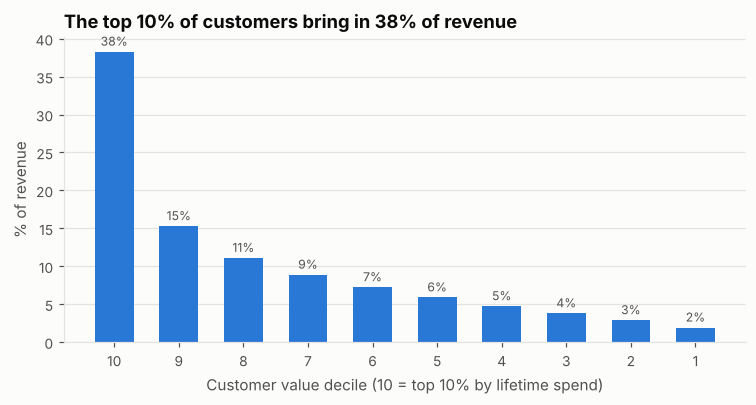

,value_decile,customers,revenue,revenue_share,cumulative_share_from_top,avg_lifetime_value,min_lifetime_value,repeat_share
0,10,9498,"6,027,281.7900",0.3829,0.3829,634.5843,318.9700,0.0940
1,9,9498,"2,406,385.0000",0.1529,0.5358,253.3570,209.1500,0.0721
2,8,9498,"1,746,473.7700",0.1110,0.6468,183.8781,163.3000,0.0435
3,7,9498,"1,398,471.3600",0.0888,0.7356,147.2385,133.0500,0.0321
4,6,9498,"1,137,984.9600",0.0723,0.8079,119.8131,107.9400,0.0254
5,5,9498,"927,005.5000",0.0589,0.8668,97.6001,87.5200,0.0166
6,4,9498,"744,608.0000",0.0473,0.9141,78.3963,70.0200,0.0108
7,3,9499,"597,072.9900",0.0379,0.9520,62.8564,55.3600,0.0064
8,2,9499,"453,966.5300",0.0288,0.9809,47.7910,40.1300,0.0021
9,1,9499,"300,967.0300",0.0191,1.0000,31.6841,9.5900,0.0008


In [12]:
deciles = run_sql_file(con, "15_customer_value_deciles")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(deciles.value_decile.astype(int).astype(str), deciles.revenue_share * 100, color=SERIES[0], width=0.6)
for x, v in enumerate(deciles.revenue_share):
    ax.text(x, v * 100 + 0.8, f"{v:.0%}", ha="center", fontsize=8, color=INK_SECONDARY)
ax.set_xlabel("Customer value decile (10 = top 10% by lifetime spend)")
ax.set_ylabel("% of revenue")
ax.set_title("The top 10% of customers bring in 38% of revenue")
plt.show()
deciles

**So what.**
- The **top 10%** of customers by spend bring in **38.3%** of revenue, and the top 20% bring in **53.6%**. The entry ticket to the top decile is about **R\$ 319** lifetime spend.
- Even in the top decile only **9.4%** are repeat buyers. High value at Olist mostly means **one big purchase**, not loyalty. That is why the segmentation in notebook 03 separates "big spenders" by recency instead of assuming they are loyal.

## Summary of EDA findings
| # | Finding | Number |
|---|---|---|
| 1 | Growth stalled in 2018 | mean MoM −1.0% (Feb–Aug 2018) after +140% YoY |
| 2 | Customers rarely return | month-1 retention 0.48%; 3.0% ever repeat |
| 3 | Lateness destroys reviews | 4.2–4.3★ on time vs 1.7★ when >1 week late |
| 4 | Lateness is regional | AL 21.4% late vs SP 4.5%; SP→RJ = 19% of late orders |
| 5 | Baskets are single-item | 90.1% one item; 2 items = +40% AOV |
| 6 | Value is concentrated but not loyal | top 10% = 38% revenue, only 9% of them repeat |

In [13]:
con.close()